In [1]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.stats as stat
from astropy.constants import eps0, c

In [12]:
data_720 = np.fromfile('test720MHz_5MSPS.dat',dtype='int16')-2**11
data_600 = np.fromfile('test600MHz_5MSPS.dat',dtype='int16')-2**11

Let's get the mean and standard deviation of the data - **remember to subtract the mean from all the data to make it centred around 0!**

In [44]:
np.random.seed(0)

for data in [data_600, data_720]:
      print(f"Mean: {np.mean(data)}\n" +
            f"Median: {np.median(data)}\n" +
            f"StDev: {np.std(data)}\n" + 
            f"Variance: {np.var(data)}\n")

      data = data - np.mean(data)

Mean: 6.0335318
Median: 6.0
StDev: 39.69238239030744
Variance: 1575.4852198183887

Mean: 6.0005736
Median: 6.0
StDev: 29.90391591867164
Variance: 894.2441872709832



We avoid the first 200000 samples because they are affected by the amplifiers starting up early on.

In [45]:
spl_size = 196608*2

subspls = [data_600[500000:spl_size+500000], data_720[500000:spl_size+500000]]

for subspl in subspls:
    subspl = subspl - np.mean(subspl)
    print(np.mean(subspl))

-1.0894063429134349e-15
0.0


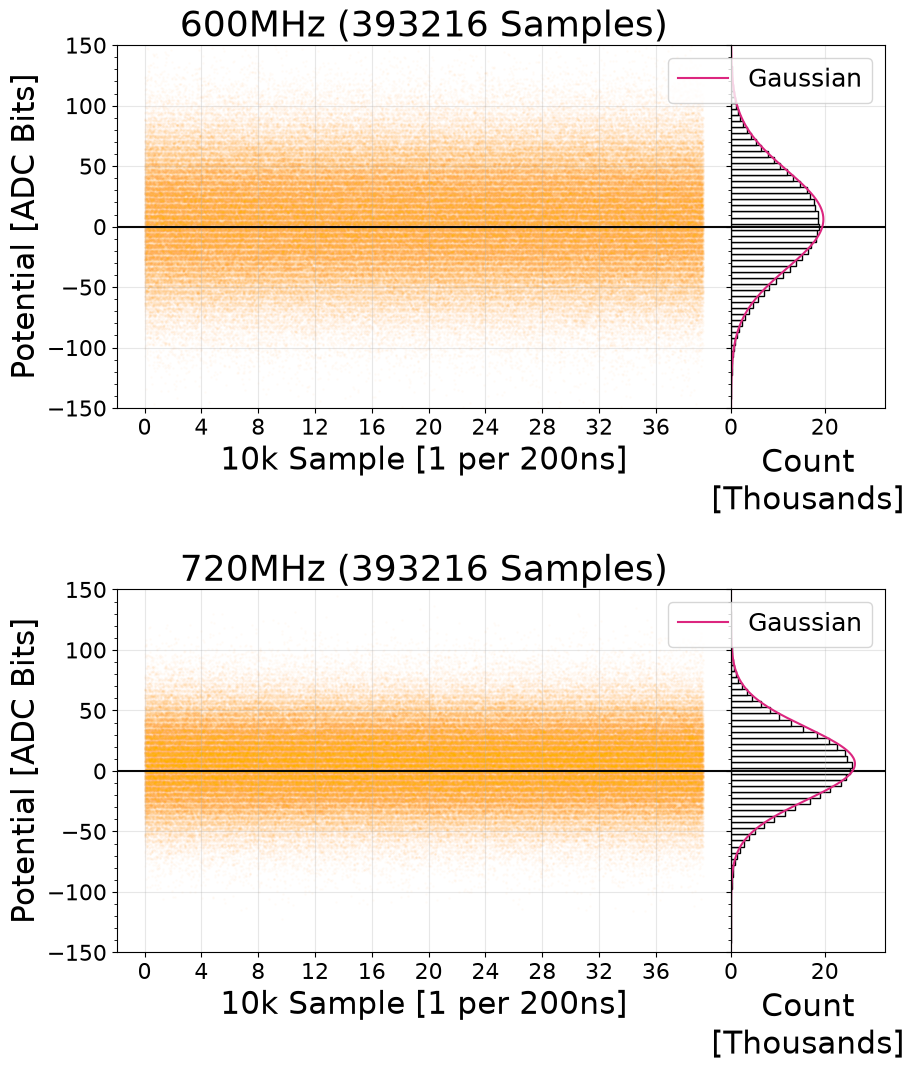

In [47]:

fig, axs = plt.subplots(2, 2, sharey=True, width_ratios=(8, 2))
plt.subplots_adjust(left=0, right=1.2, top=2, wspace=0, hspace=0.5)
lin_range = np.arange(0, spl_size, 1)

i = 0

for subspl in subspls:
    axs[i][0].axhline(0, color='#080808')
    axs[i][1].axhline(0, color='#080808')

    axs[i][0].set_yticks(np.arange(-150, 150, 10), minor=True)
    axs[i][0].set_xticks(np.arange(0, len(subspl), 40000))

    axs[i][0].scatter(lin_range, subspl, color='#FFB000', s=1, alpha=0.02)
    axs[i][0].set_ylim(-150, 150)

    axs[i][1].hist(subspl, bins=np.arange(-140, 140, 5), edgecolor='black', color='white', orientation="horizontal", align="left")

    gauss_range = np.arange(-150, 151, 1)
    axs[i][1].plot(stat.norm.pdf(gauss_range, loc=np.mean(subspl), scale=np.std(subspl))*10**6.3, gauss_range, 
                label="Gaussian", color="#DC267F")

    axs[i][1].set_xlim(0, spl_size/12)

    axs[i][0].xaxis.set_major_formatter(lambda x,y: int(x / 10000))
    axs[i][1].xaxis.set_major_formatter(lambda x,y: int(x / 1000))

    name = "600MHz" if i == 0 else "720MHz"

    axs[i][0].set_title(f"{name} ({spl_size} Samples)", fontsize=26)
    axs[i][0].set_ylabel("Potential [ADC Bits]", fontsize=22)
    axs[i][0].set_xlabel("10k Sample [1 per 200ns]", fontsize=22)

    axs[i][1].set_xlabel("Count\n[Thousands]", fontsize=22)

    axs[i][0].tick_params(labelsize=16)
    axs[i][1].tick_params(labelsize=16)

    axs[i][0].grid(alpha=0.3, zorder=-10)
    axs[i][1].grid(alpha=0.3, zorder=-10)

    axs[i][1].legend(fontsize=18, loc="upper right")

    i += 1



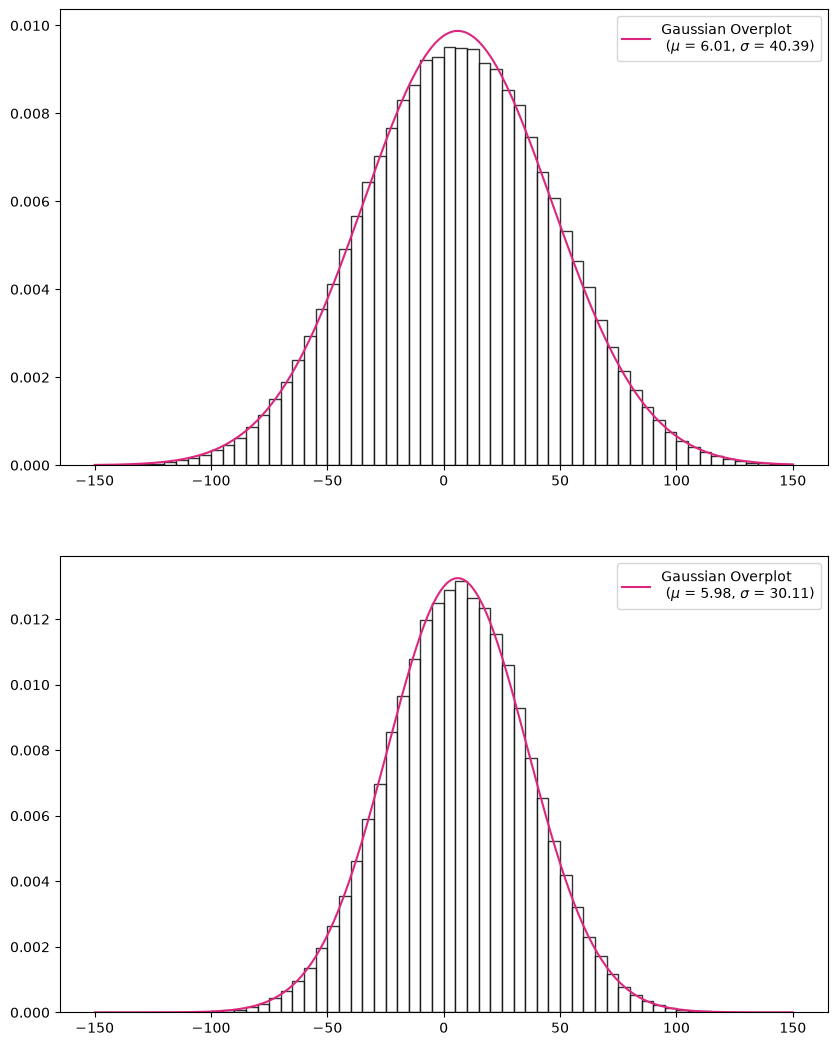

In [49]:
# Histogram only
fix, axs = plt.subplots(2, 1)
plt.subplots_adjust(left=0, right=1.2, top=2.2, hspace=0.2)

i = 0

for subspl in subspls:
    axs[i].hist(subspl, bins=np.arange(-150, 151, 5), edgecolor='black', color='white', alpha=0.8, density=True)

    lin_range = np.arange(-150, 151, 1)
    axs[i].plot(lin_range, stat.norm.pdf(lin_range, loc=np.mean(subspl), scale=np.std(subspl)), 
            label=f"Gaussian Overplot \n ($\mu$ = {np.round(np.mean(subspl), 2)}, $\sigma$ = {np.round(np.std(subspl), 2)})", color="#DC267F")
    axs[i].legend()
    i += 1

In [53]:
fft_size = 2048

cuts = []
powers = []
avg_power = []

for subspl in subspls:
    j = 0
    subspl_cuts = []
    while j < spl_size - fft_size:
        subspl_cuts.append(subspl[j:j+fft_size])
        j += fft_size

    ffts = [] 

    for spl in subspl_cuts:
        ffts.append(np.fft.fft(spl, n=fft_size))

    subspl_powers = []

    for fft in ffts:
        elems = []
        for elem in fft:
            elems.append(elem.real ** 2 + elem.imag ** 2)
        subspl_powers.append(elems)
        
    subspl_powers = np.array(subspl_powers)

    avg_power.append(np.mean(subspl_powers, axis=0))
    cuts.append(subspl_cuts)
    powers.append(subspl_powers)

Fractional uncertainty from Radiometer Equation: 0.002255274489021976 [0.226%]
Fractional uncertainty from Radiometer Equation: 0.002255274489021976 [0.226%]


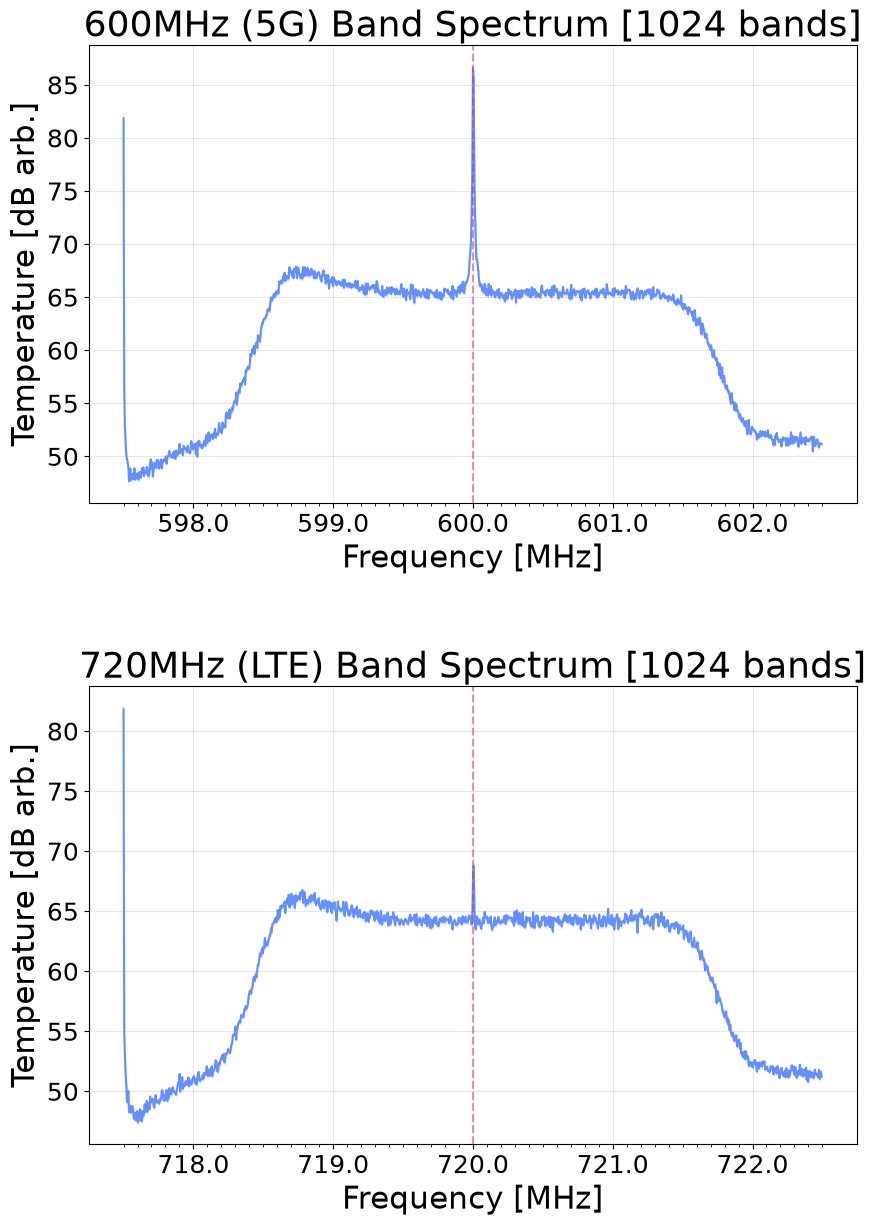

In [61]:
##########
# Variables from AirSpy setup
##########
spl_rate = 5000000
cadence = 1/spl_rate
targets = [600000000, 720000000]
LOS = [targets[0] - 3*spl_rate/4, targets[1] - 3*spl_rate/4]

##########
# Scatter (0) or Line (1)?
##########
line = True

# reflect LO change in AirSpy firmware
for i in range(len(LOS)):
    LOS[i] += (1/cadence)/4 

fig, axs = plt.subplots(2, 1)
plt.subplots_adjust(left=0, right=1.2, top=2.4, hspace=0.4)

for i in range(len(LOS)):
    lin_range = np.arange(LOS[i], 1/cadence + LOS[i], 1 / (cadence * fft_size/2))

    if line:
        axs[i].plot(lin_range, 10*np.log10(avg_power[i][:fft_size//2]), color="#648FFF")
    else:
        axs[i].scatter(lin_range, 10*np.log10(avg_power[i][:fft_size//2]), s=3, color="#648FFF")

    axs[i].axvline(targets[i], color="#DC267F", ls="--", alpha=0.5)

    title = "600MHz (5G)" if i == 0 else "720MHz (LTE)"

    axs[i].set_xlabel("Frequency [MHz]", fontsize=22)
    axs[i].set_ylabel("Temperature [dB arb.]", fontsize=22)
    axs[i].set_title(f"{title} Band Spectrum [{fft_size//2} bands]", fontsize=26)

    axs[i].set_xticks(np.arange(targets[i] - spl_rate/2, targets[i] + spl_rate/2 + 1, 100000), minor=True)
    axs[i].xaxis.set_major_formatter(lambda x,y: (x / 1000000))
    axs[i].tick_params(labelsize=18)

    axs[i].grid(alpha=0.3)

    # radiometer equation (T \propto P)
    time = (spl_size) * cadence
    dv = 1 / (2 * cadence)

    frac_radio = 1/(time * dv)**0.5
    print(f"Fractional uncertainty from Radiometer Equation: {frac_radio} [{np.round(frac_radio * 100, 3)}%]")

    # plot the fractional uncertainty
    axs[i].fill_between(lin_range, 10*np.log10(avg_power[i][:fft_size//2]) - 10*np.log10(avg_power[i][:fft_size//2])*frac_radio,
                                10*np.log10(avg_power[i][:fft_size//2]) + 10*np.log10(avg_power[i][:fft_size//2])*frac_radio,
                                color="#648FFF", alpha=0.2)

There's very noisy peaks at the start because of the AirSpy itself and DC offset. This is a systematic (although partially random) error which is known to affect the first few bands in the Fourier transform, so we can omit them.

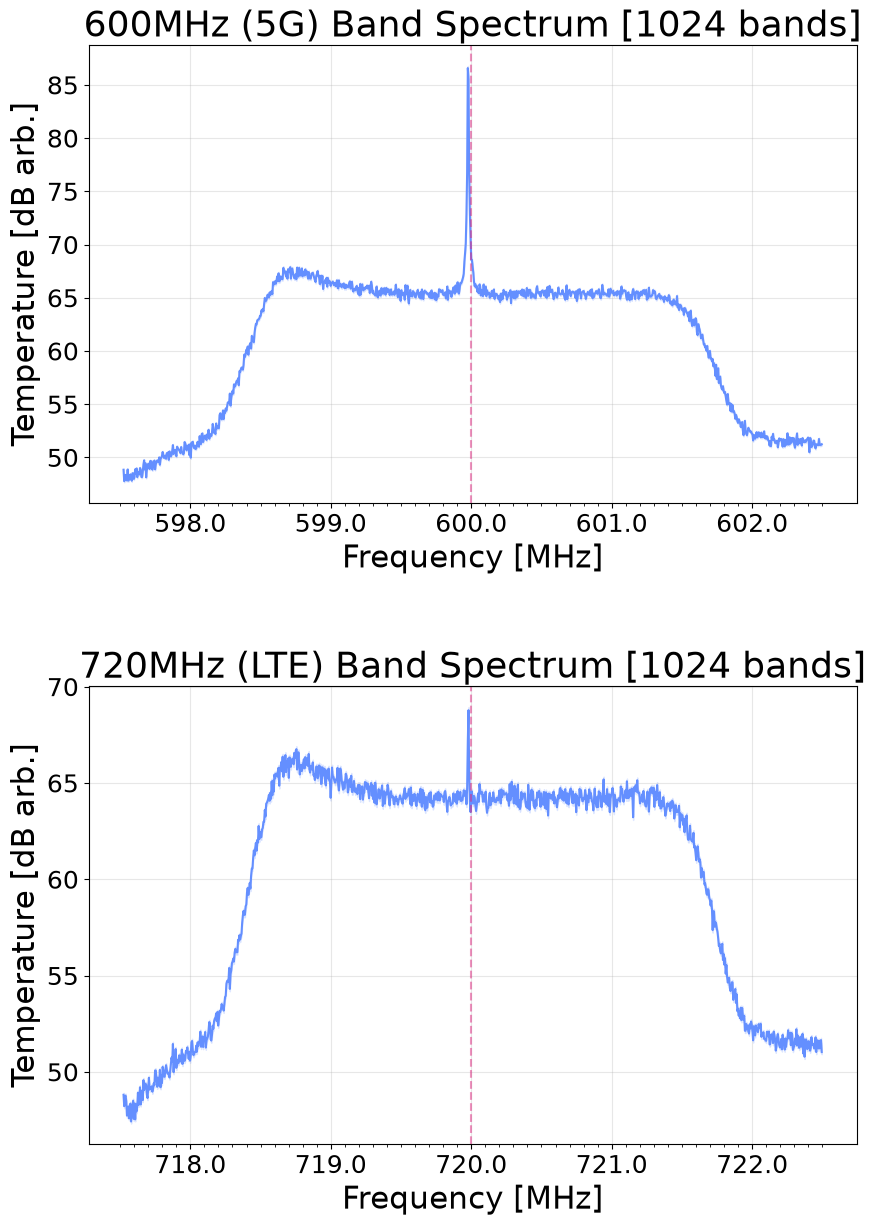

In [66]:
##########
# Variables from AirSpy setup
##########
spl_rate = 5000000
cadence = 1/spl_rate
targets = [600000000, 720000000]
LOS = [targets[0] - 3*spl_rate/4, targets[1] - 3*spl_rate/4]

##########
# Scatter (0) or Line (1)?
##########
line = True

# reflect LO change in AirSpy firmware
for i in range(len(LOS)):
    LOS[i] += (1/cadence)/4 

fig, axs = plt.subplots(2, 1)
plt.subplots_adjust(left=0, right=1.2, top=2.4, hspace=0.4)

for i in range(len(LOS)):

    # truncate first 5 points to omit DC offset
    lin_range = np.arange(LOS[i] + 5 / (cadence * fft_size/2), 1/cadence + LOS[i], 1 / (cadence * fft_size/2))

    if line:
        axs[i].plot(lin_range, 10*np.log10(avg_power[i][5:fft_size//2]), color="#648FFF")
    else:
        axs[i].scatter(lin_range, 10*np.log10(avg_power[i][5:fft_size//2]), s=3, color="#648FFF")

    axs[i].axvline(targets[i], color="#DC267F", ls="--", alpha=0.5)

    title = "600MHz (5G)" if i == 0 else "720MHz (LTE)"

    axs[i].set_xlabel("Frequency [MHz]", fontsize=22)
    axs[i].set_ylabel("Temperature [dB arb.]", fontsize=22)
    axs[i].set_title(f"{title} Band Spectrum [{fft_size//2} bands]", fontsize=26)

    axs[i].set_xticks(np.arange(targets[i] - spl_rate/2, targets[i] + spl_rate/2 + 1, 100000), minor=True)
    axs[i].xaxis.set_major_formatter(lambda x,y: (x / 1000000))
    axs[i].tick_params(labelsize=18)

    axs[i].grid(alpha=0.3)

    # radiometer equation (T \propto P)
    time = (spl_size) * cadence
    dv = 1 / (2 * cadence)

    frac_radio = 1/(time * dv)**0.5

    # plot the fractional uncertainty
    axs[i].fill_between(lin_range, 10*np.log10(avg_power[i][5:fft_size//2]) - 10*np.log10(avg_power[i][5:fft_size//2])*frac_radio,
                                10*np.log10(avg_power[i][5:fft_size//2]) + 10*np.log10(avg_power[i][5:fft_size//2])*frac_radio,
                                color="#648FFF", alpha=0.2)